# CIRRUS++ — Complete Synthetic Evaluation of Five Domains

**Executed analysis notebook** for industrial, energy, physiological, finance, and network time series. A separate eye-tracking evaluation was conducted previously.

This notebook **analyses 33,600 previously executed preprocessing pipelines**. The run generation and execution are documented in `run_full_five_domains.py` and `orchestrate.py`. The intrinsic quality index and preprocessing operators were implemented in a local transcription informed by `cirruspp_core.py`; **a direct parity test against the application core remains outstanding**.


In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
p=Path.cwd()
r=pd.read_csv(p/'results_all.csv')
s=pd.read_csv(p/'summary_all.csv')
a=pd.read_csv(p/'domain_severity_summary.csv')
o=pd.read_csv(p/'domain_overview.csv')
c=pd.read_csv(p/'dimension_correlations.csv')
print(f"Evaluations: {len(r):,}; Domains: {r.domain.nunique()}; Scenarios: {len(s)}")
assert len(r)==33_600
display(o.round(3))


Evaluations: 33,600; Domains: 5; Scenarios: 100


,domain,median_rho,mean_rho,median_regret,wins,top5_hits,n,median_best_nrmse,median_qwinner_nrmse
0,energy,-0.825,-0.739,2.720,0,0,15,0.107,0.304
1,finance,-0.490,-0.496,1.428,0,2,15,0.457,0.614
2,industrial,-0.734,-0.634,1.356,0,0,15,0.238,0.312
3,network,-0.305,-0.295,1.548,0,0,15,0.426,0.634
4,physiological,-0.925,-0.884,1.863,1,5,15,0.087,0.128


## Experimental setup

- Data: the same five domain-specific synthetic generators in `cirrus_eval.py`, **480 samples** per time series, seeds 42–46.
- Corruption: 0/5/10/15% per channel; approximately half missing at random (MCAR) and half additive spikes (4–9 times the channel standard deviation), using the same `corrupt_nested` procedure as the initial experiment.
- Search space: 7 imputation methods × 6 outlier methods × 4 smoothing methods × 2 stage orders = **336 cleaning configurations**. Scaling is disabled to preserve error units.
- Primary metric: mean of **channel-standardized RMSE values** over all samples. A pipeline with unresolved output values receives missing NRMSE (no additional fallback imputation).
- The 0% control contains no *additional* injected corruption; the generator signal is not necessarily noise-free.
- Q is an intrinsic domain-weighted score, **not a ground-truth quality measure**. Output-scaling sensitivity is outside the scope of this experiment.


In [2]:
display(a[['domain','severity_pct','median_corrupted_q','median_spearman','median_best_nrmse','median_q_winner_nrmse','qmax_hits']].round(3))


,domain,severity_pct,median_corrupted_q,median_spearman,median_best_nrmse,median_q_winner_nrmse,qmax_hits
0,energy,0,91.396,0.730,0.000,0.180,0
1,energy,5,70.945,-0.586,0.044,0.313,0
2,energy,10,67.195,-0.825,0.107,0.304,0
3,energy,15,65.702,-0.926,0.119,0.298,0
4,finance,0,79.945,-0.517,0.000,0.382,0
5,finance,5,60.445,-0.542,0.361,0.575,0
6,finance,10,63.814,-0.490,0.457,0.614,0
7,finance,15,65.333,-0.419,0.504,0.701,0
8,industrial,0,82.343,0.960,0.000,0.320,0
9,industrial,5,72.531,-0.307,0.176,0.300,0


## Association between Q and reconstruction error

A negative Spearman correlation is expected. However, a favorable correlation does not guarantee that the pipeline with the highest intrinsic quality index also minimizes reconstruction error.


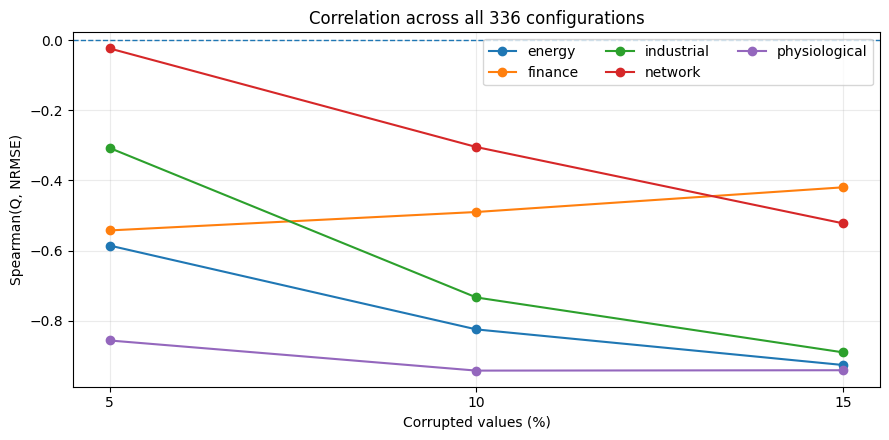

In [3]:
fig,ax=plt.subplots(figsize=(9,4.5))
for domain,g in a[a.severity_pct>0].groupby('domain'):
    ax.plot(g.severity_pct,g.median_spearman,marker='o',label=domain)
ax.axhline(0,ls='--',lw=1)
ax.set_xticks([5,10,15]);ax.set_xlabel('Corrupted values (%)');ax.set_ylabel('Spearman(Q, NRMSE)')
ax.set_title('Correlation across all 336 configurations');ax.legend(ncol=3);ax.grid(alpha=.25)
plt.tight_layout();plt.show()


## Does the highest quality score identify the lowest reconstruction error?


Q-max includes NRMSE-optimal candidate: 1 of 75 Szenarien
Top-five Q includes NRMSE-optimal candidate: 7 of 75


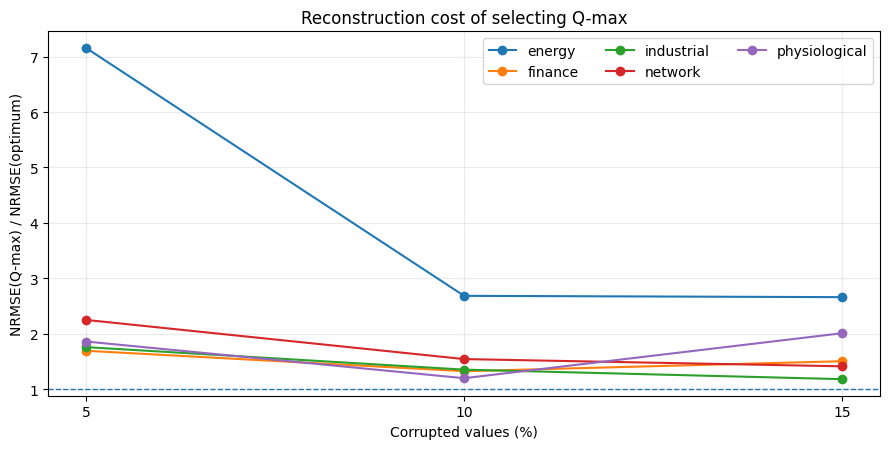

In [4]:
q=s[s.severity_pct>0]
print('Q-max includes NRMSE-optimal candidate:', int(q.qmax_ties_include_rmse_min.sum()),'of',len(q),'Szenarien')
print('Top-five Q includes NRMSE-optimal candidate:', int(q.top5_contains_optimum.sum()),'of',len(q))
fig,ax=plt.subplots(figsize=(9,4.6))
for domain,g in q.groupby('domain'):
    med=g.groupby('severity_pct').nrmse_regret_ratio.median()
    ax.plot(med.index,med.values,marker='o',label=domain)
ax.axhline(1,ls='--',lw=1);ax.set_xticks([5,10,15]);ax.set_ylabel('NRMSE(Q-max) / NRMSE(optimum)')
ax.set_xlabel('Corrupted values (%)');ax.set_title('Reconstruction cost of selecting Q-max')
ax.legend(ncol=3);ax.grid(alpha=.25);plt.tight_layout();plt.show()


## Controlled corruption: Does the index respond monotonically?

For a fixed seed and clean input, an increase in intrinsic quality under stronger artificial corruption is a warning sign. It does not, by itself, prove that every quality component is incorrectly defined.


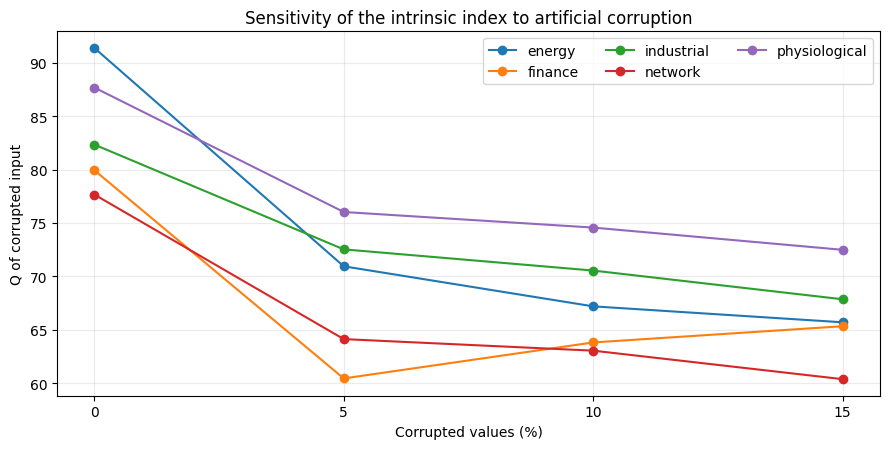

In [5]:
fig,ax=plt.subplots(figsize=(9,4.6))
for domain,g in a.groupby('domain'):
    ax.plot(g.severity_pct,g.median_corrupted_q,marker='o',label=domain)
ax.set_xticks([0,5,10,15]);ax.set_xlabel('Corrupted values (%)');ax.set_ylabel('Q of corrupted input')
ax.set_title('Sensitivity of the intrinsic index to artificial corruption');ax.legend(ncol=3);ax.grid(alpha=.25)
plt.tight_layout();plt.show()


## Ablation: Individual quality dimensions

A component that remains constant within a group has undefined rank correlation. Comparing component-level associations generates hypotheses but does not justify new causal weight choices.


In [6]:
z=c[c.severity_pct==10].pivot(index='domain',columns='component',values='median_spearman')
display(z.round(3))


component,completeness,continuity,correlation,distribution,plausibility,stability
domain,,,,,,
energy,NaN,NaN,-0.821,0.110,-0.731,-0.818
finance,NaN,NaN,-0.145,-0.423,-0.484,0.127
industrial,NaN,NaN,-0.870,-0.127,-0.783,-0.034
network,NaN,NaN,-0.080,-0.232,-0.439,0.552
physiological,NaN,NaN,-0.947,-0.555,-0.749,-0.883


## Methodological limitations and publication considerations

1. The generators are synthetic and in part deliberately simplified. They cannot represent all natural artifacts or genuine events.
2. Only five random seeds and one corruption family were considered; the 336 configurations are not independent statistical observations.
3. Certain outlier operators may interpolate existing NaNs; some stage orders and configurations produce identical outputs.
4. NRMSE measures reference reconstruction, not downstream utility (e.g., classification accuracy or event preservation).
5. The benchmark uses a local transcription of CIRRUS++ methods. Before making strict claims about the deployed application, run `test_upstream_parity.py` against a pinned version of the application core and resolve differences.
6. The full eye-tracking evaluation is reported separately; this notebook covers the other five synthetic domains only.
